**Capstone Project: Store Sales & Profit Analytics**

**Setup (Google Colab)**

In [1]:
import pandas as pd, numpy as np, warnings, os
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', rc={'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']})
os.makedirs('figs', exist_ok=True)
PAL = '#4A90C8'; PAL2 = '#9DC3E6'; ACC = '#E07B39'

try:
    from google.colab import files
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
except ImportError:
    fname = 'store_sales_data.csv'
df = pd.read_csv(fname)
print(df.shape)
df.head()

(100000, 25)


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Ship Date,Ship Mode,State,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2023,Large,Tier 1,Fast Food,East,...,2020-04-18,Same Day,West Bengal,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2022,Medium,Tier 2,Fast Food,East,...,2021-01-11,Standard Class,Punjab,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2023,Large,Village,Electric Appliances,South,...,2020-08-16,Second Class,Gujarat,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,2021-10-16,First Class,West Bengal,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2021,Small,Village,Sessional Fruits & Vegetables,West,...,2019-01-25,Standard Class,Delhi,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93


In [2]:
print(df.dtypes)
print('\nMissing values per column:', int(df.isna().sum().sum()))
print('Duplicate Order IDs:', df['Order ID'].duplicated().sum())

Customer ID              str
Customer Name            str
Last Name                str
Date of Birth            str
Sales                float64
Year                   int64
Outlet Type              str
City Type                str
Category of Goods        str
Region                   str
Country                  str
Segment                  str
Sales Date               str
Order ID                 str
Order Date               str
Ship Date                str
Ship Mode                str
State                    str
Postal Code            int64
Product ID               str
Sub-Category             str
Product Name             str
Quantity               int64
Discount             float64
Profit               float64
dtype: object

Missing values per column: 0
Duplicate Order IDs: 0


**Data preparation and classification**

In [3]:
for c in ['Sales Date','Order Date','Ship Date']:
    df[c] = pd.to_datetime(df[c])
df['Ship_Days'] = (df['Ship Date'] - df['Order Date']).dt.days
print(df['Ship_Days'].describe())

classification = pd.DataFrame({
 'Variable': ['Sales','Profit','Quantity','Discount','Ship_Days','Outlet Type','City Type','Category of Goods','Region','Segment','Ship Mode','State','Sales Date'],
 'Type': ['Numeric (continuous)','Numeric (continuous)','Numeric (discrete)','Numeric (continuous)','Numeric (discrete)',
          'Categorical (ordinal)','Categorical (ordinal)','Categorical (nominal)','Categorical (nominal)','Categorical (nominal)','Categorical (ordinal)','Categorical (nominal)','Date-time'],
 'Role': ['Feature / TS target','Regression target','Feature','Feature','Feature','Feature','Feature','Feature','Feature','Feature','Feature','Not used (ID-like)','TS index']})
classification

count    100000.000000
mean          3.991060
std           2.006554
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max           7.000000
Name: Ship_Days, dtype: float64


,Variable,Type,Role
0,Sales,Numeric (continuous),Feature / TS target
1,Profit,Numeric (continuous),Regression target
2,Quantity,Numeric (discrete),Feature
3,Discount,Numeric (continuous),Feature
4,Ship_Days,Numeric (discrete),Feature
5,Outlet Type,Categorical (ordinal),Feature
6,City Type,Categorical (ordinal),Feature
7,Category of Goods,Categorical (nominal),Feature
8,Region,Categorical (nominal),Feature
9,Segment,Categorical (nominal),Feature


**Data description: central tendency, SD and correlation**

In [4]:
num = ['Sales','Profit','Quantity','Discount','Ship_Days']
desc = pd.DataFrame({
  'Mean': df[num].mean(), 'Median': df[num].median(), 'Mode': df[num].mode().iloc[0],
  'Std Dev': df[num].std(), 'Min': df[num].min(), 'Max': df[num].max(), 'Skewness': df[num].skew()}).round(3)
desc.to_csv('desc_stats.csv')
desc

,Mean,Median,Mode,Std Dev,Min,Max,Skewness
Sales,25084.410,25134.695,1842.94,14403.188,100.57,49999.89,-0.007
Profit,3755.305,3317.450,889.53,2639.852,6.52,14563.67,0.806
Quantity,5.494,5.000,2.00,2.876,1.00,10.00,-0.000
Discount,0.251,0.250,0.31,0.144,0.00,0.50,-0.010
Ship_Days,3.991,4.000,1.00,2.007,1.00,7.00,0.003


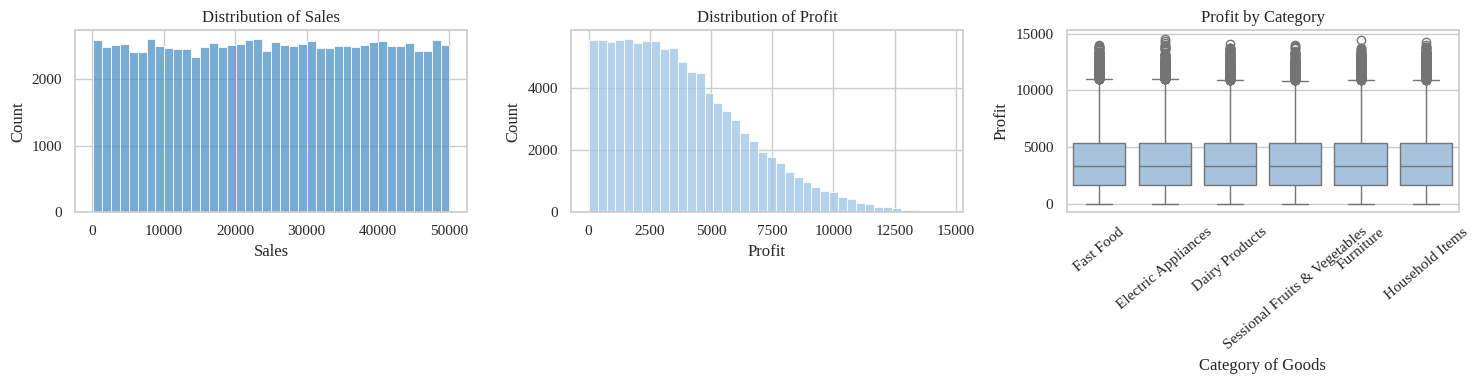

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['Sales'], bins=40, color=PAL, ax=ax[0]); ax[0].set_title('Distribution of Sales')
sns.histplot(df['Profit'], bins=40, color=PAL2, ax=ax[1]); ax[1].set_title('Distribution of Profit')
sns.boxplot(data=df, x='Category of Goods', y='Profit', color=PAL2, ax=ax[2])
ax[2].set_title('Profit by Category'); ax[2].tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.savefig('figs/fig1_distributions.png', dpi=160); plt.show()

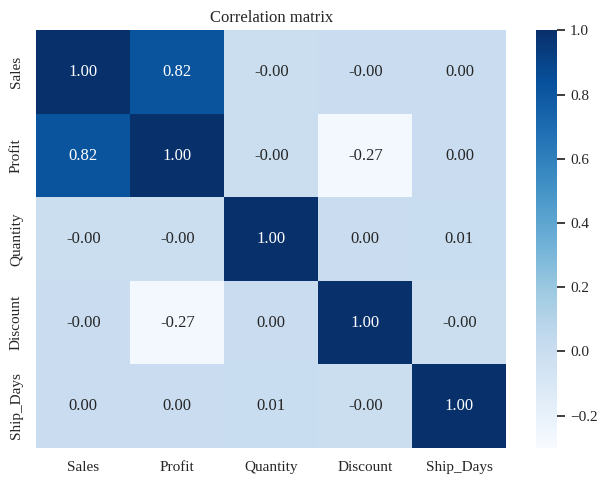

,Sales,Profit,Quantity,Discount,Ship_Days
Sales,1.000,0.818,-0.002,-0.000,0.001
Profit,0.818,1.000,-0.004,-0.273,0.001
Quantity,-0.002,-0.004,1.000,0.004,0.005
Discount,-0.000,-0.273,0.004,1.000,-0.003
Ship_Days,0.001,0.001,0.005,-0.003,1.000


In [6]:
corr = df[num].corr().round(3)
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap='Blues', vmin=-0.3, vmax=1, fmt='.2f')
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('figs/fig2_corr.png', dpi=160); plt.show()
corr

**Regression analysis for feature selection**

In [7]:
cats = ['Outlet Type','City Type','Category of Goods','Region','Segment','Ship Mode']
X = pd.get_dummies(df[['Sales','Quantity','Discount','Ship_Days']+cats], columns=cats, drop_first=True).astype(float)
y = df['Profit']
Xc = sm.add_constant(X)
ols = sm.OLS(y, Xc).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.744
Method:                 Least Squares   F-statistic:                 1.450e+04
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:15:15   Log-Likelihood:            -8.6170e+05
No. Observations:              100000   AIC:                         1.723e+06
Df Residuals:                   99979   BIC:                         1.724e+06
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                                      coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------

In [8]:
fig = plt.figure(figsize=(11, 12)); plt.axis('off')
plt.text(0, 1, str(ols.summary()), family='monospace', fontsize=7.2, va='top')
plt.savefig('figs/fig3_ols_summary.png', dpi=170, bbox_inches='tight'); plt.close()

coef = pd.DataFrame({'Coefficient': ols.params, 'p-value': ols.pvalues}).drop('const')
coef['Significant (p<0.05)'] = np.where(coef['p-value'] < 0.05, 'Yes', 'No')
coef = coef.round(4)
coef.to_csv('ols_coef.csv')
print('R-squared: %.4f | Adj R-squared: %.4f | F p-value: %.3g' % (ols.rsquared, ols.rsquared_adj, ols.f_pvalue))
coef.sort_values('p-value')

R-squared: 0.7436 | Adj R-squared: 0.7435 | F p-value: 0


,Coefficient,p-value,Significant (p<0.05)
Sales,0.1499,0.0000,Yes
Discount,-4988.1511,0.0000,Yes
Outlet Type_Medium,21.5577,0.0369,Yes
City Type_Tier 2,-17.0873,0.0983,No
Outlet Type_Small,16.3036,0.1159,No
Category of Goods_Fast Food,21.3685,0.1445,No
Ship Mode_Same Day,12.9615,0.2780,No
Region_North,-12.7954,0.2839,No
Ship Mode_Standard Class,10.9167,0.3611,No
Ship Mode_Second Class,10.2495,0.3913,No


In [9]:
Z = (X[['Sales','Quantity','Discount','Ship_Days']] - X[['Sales','Quantity','Discount','Ship_Days']].mean()) / X[['Sales','Quantity','Discount','Ship_Days']].std()
zfit = sm.OLS((y - y.mean())/y.std(), sm.add_constant(Z)).fit()
std_beta = zfit.params.drop('const').round(4).sort_values(key=abs, ascending=False)
print('Standardised coefficients (numeric features):'); print(std_beta)

from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns).round(2)
print('\nMax VIF:', vif.max())

Standardised coefficients (numeric features):
Sales        0.8180
Discount    -0.2727
Quantity    -0.0008
Ship_Days    0.0002
dtype: float64



Max VIF: 1.67


**Decision Tree Regressor**

Decision Tree  R2 = 0.7319  RMSE = 1368.4
OLS (test)     R2 = 0.7397  RMSE = 1348.3


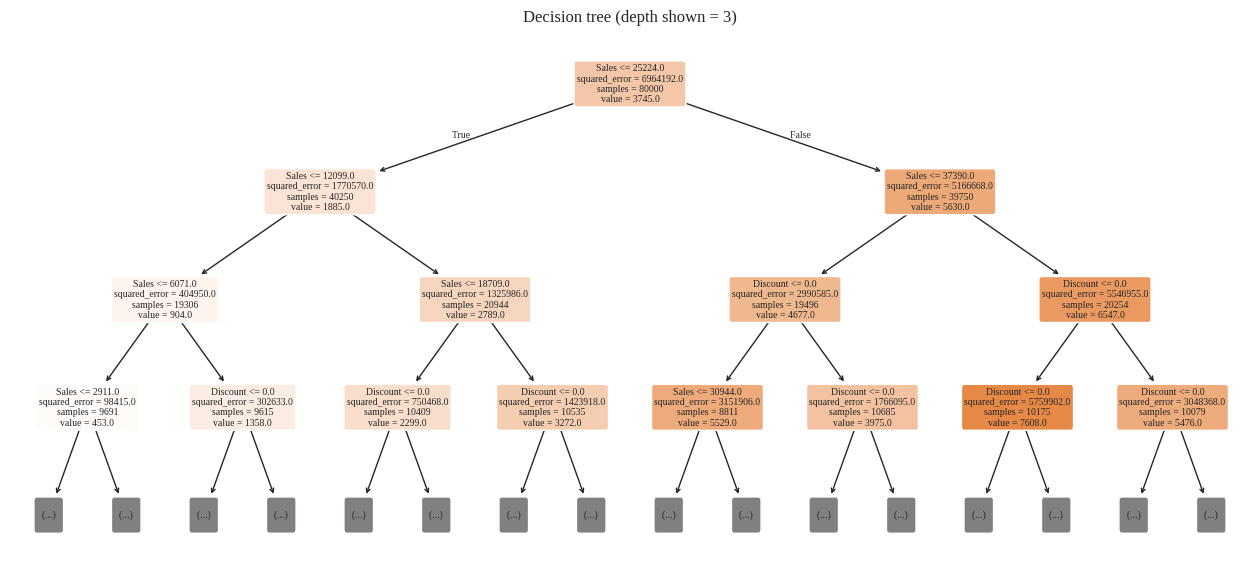

In [10]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=200, random_state=42).fit(Xtr, ytr)
pred = tree.predict(Xte)
tree_r2 = r2_score(yte, pred); tree_rmse = np.sqrt(mean_squared_error(yte, pred))

ols_tr = sm.OLS(ytr, sm.add_constant(Xtr)).fit()
ols_pred = ols_tr.predict(sm.add_constant(Xte))
print('Decision Tree  R2 = %.4f  RMSE = %.1f' % (tree_r2, tree_rmse))
print('OLS (test)     R2 = %.4f  RMSE = %.1f' % (r2_score(yte, ols_pred), np.sqrt(mean_squared_error(yte, ols_pred))))

plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True, fontsize=7, max_depth=3, precision=0)
plt.title('Decision tree (depth shown = 3)'); plt.savefig('figs/fig4_tree.png', dpi=150, bbox_inches='tight'); plt.show()

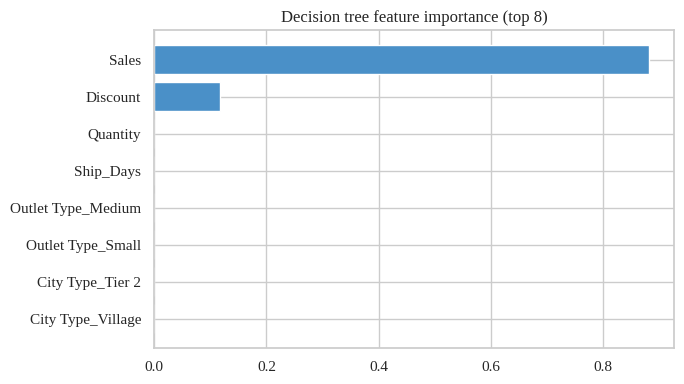

Sales                 0.8831
Discount              0.1169
Quantity              0.0000
Ship_Days             0.0000
Outlet Type_Medium    0.0000
Outlet Type_Small     0.0000
City Type_Tier 2      0.0000
City Type_Village     0.0000
dtype: float64

In [11]:
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
top = imp.head(8)[::-1]
plt.figure(figsize=(7, 4)); plt.barh(top.index, top.values, color=PAL)
plt.title('Decision tree feature importance (top 8)'); plt.tight_layout()
plt.savefig('figs/fig5_importance.png', dpi=160); plt.show()
imp.head(8).round(4)

**Time series analysis (monthly Sales)**

(60,) 2019-01-01 2023-12-01


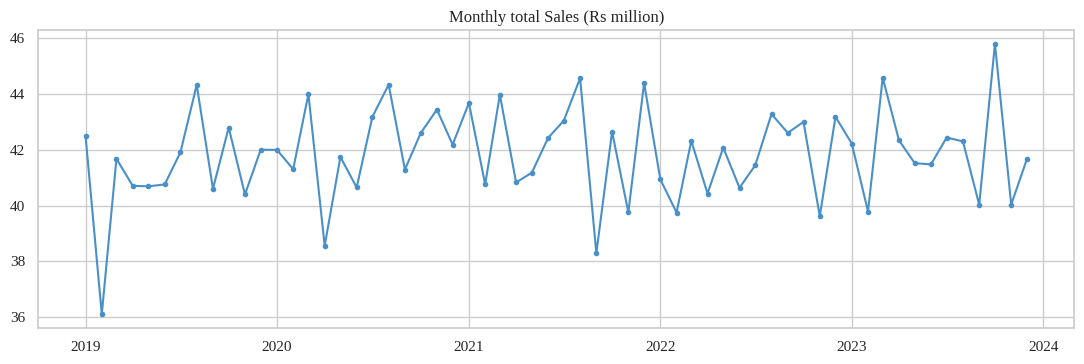

count    60.00
mean     41.81
std       1.72
min      36.11
25%      40.70
50%      41.95
75%      42.84
max      45.78
Name: Sales, dtype: float64

In [12]:
ts = df.set_index('Sales Date')['Sales'].resample('MS').sum() / 1e6
print(ts.shape, ts.index.min().date(), ts.index.max().date())
plt.figure(figsize=(11, 3.8)); plt.plot(ts, color=PAL, marker='o', ms=3)
plt.title('Monthly total Sales (Rs million)'); plt.tight_layout(); plt.savefig('figs/fig6_ts.png', dpi=160); plt.show()
ts.describe().round(2)

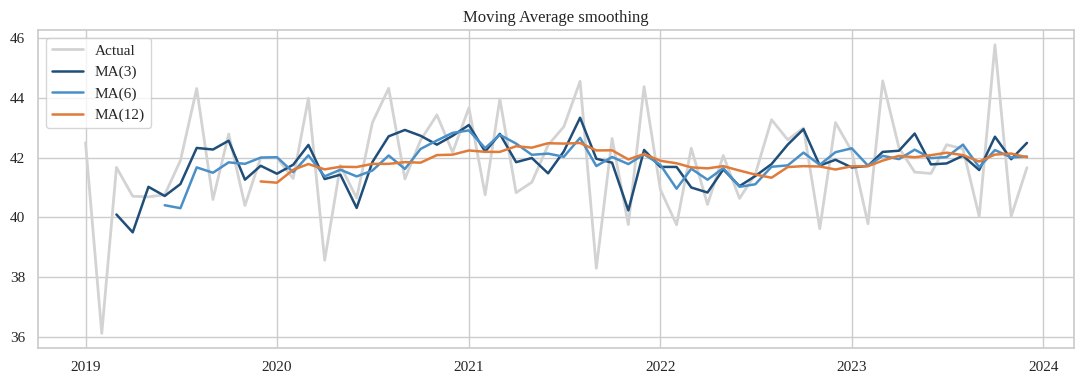

In [13]:
train, test = ts.iloc[:-12], ts.iloc[-12:]
def metrics(actual, fc):
    return mean_absolute_error(actual, fc), np.sqrt(mean_squared_error(actual, fc)), np.mean(np.abs((actual-fc)/actual))*100

ma = {k: ts.rolling(k).mean() for k in (3, 6, 12)}
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ts, label='Actual', color='lightgray', lw=2)
for k, c in zip((3, 6, 12), ('#1F4E79', '#4A90C8', '#E07B39')):
    ax.plot(ma[k], label=f'MA({k})', color=c, lw=1.8)
ax.set_title('Moving Average smoothing'); ax.legend(); plt.tight_layout()
plt.savefig('figs/fig7_ma.png', dpi=160); plt.show()

res = []
for k in (3, 6, 12):
    fc = ts.rolling(k).mean().shift(1).iloc[-12:]
    res.append((f'Moving Average (k={k})',) + metrics(test, fc))

SES  (optimised) alpha = 0.000
Holt (optimised) alpha = 0.000, beta = 0.000


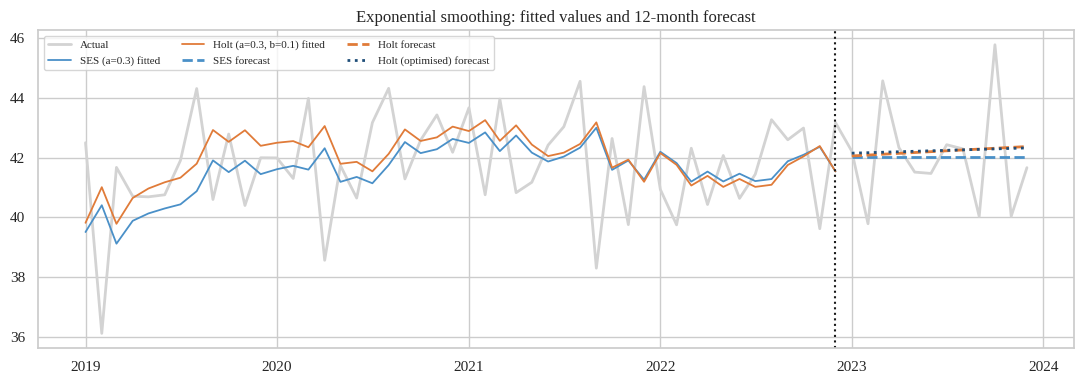

,MAE (Rs M),RMSE (Rs M),MAPE (%)
Method,,,
Moving Average (k=3),1.463,1.909,3.452
Moving Average (k=6),1.393,1.901,3.292
Moving Average (k=12),1.326,1.762,3.124
"SES (optimised, a~0)",1.262,1.719,2.960
SES (a=0.3),1.262,1.700,2.980
Holt double exp. (optimised),1.278,1.717,3.033
"Holt double exp. (a=0.3, b=0.1)",1.291,1.718,3.062


In [14]:
ses = SimpleExpSmoothing(train, initialization_method='estimated').fit()
ses_fc = ses.forecast(12)
ses3 = SimpleExpSmoothing(train, initialization_method='estimated').fit(smoothing_level=0.3, optimized=False)
ses3_fc = ses3.forecast(12)
holt = Holt(train, initialization_method='estimated').fit()
holt_fc = holt.forecast(12)
holt3 = Holt(train, initialization_method='estimated').fit(smoothing_level=0.3, smoothing_trend=0.1, optimized=False)
holt3_fc = holt3.forecast(12)
print('SES  (optimised) alpha = %.3f' % ses.params['smoothing_level'])
print('Holt (optimised) alpha = %.3f, beta = %.3f' % (holt.params['smoothing_level'], holt.params['smoothing_trend']))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ts, color='lightgray', lw=2, label='Actual')
ax.plot(ses3.fittedvalues, color='#4A90C8', lw=1.3, label='SES (a=0.3) fitted')
ax.plot(holt3.fittedvalues, color='#E07B39', lw=1.3, label='Holt (a=0.3, b=0.1) fitted')
ax.plot(ses3_fc, '--', color='#4A90C8', lw=2, label='SES forecast')
ax.plot(holt3_fc, '--', color='#E07B39', lw=2, label='Holt forecast')
ax.plot(holt_fc, ':', color='#1F4E79', lw=2, label='Holt (optimised) forecast')
ax.axvline(train.index[-1], color='k', ls=':'); ax.legend(ncol=3, fontsize=8)
ax.set_title('Exponential smoothing: fitted values and 12-month forecast'); plt.tight_layout()
plt.savefig('figs/fig8_exp.png', dpi=160); plt.show()

res.append(('SES (optimised, a~0)',) + metrics(test, ses_fc))
res.append(('SES (a=0.3)',) + metrics(test, ses3_fc))
res.append(('Holt double exp. (optimised)',) + metrics(test, holt_fc))
res.append(('Holt double exp. (a=0.3, b=0.1)',) + metrics(test, holt3_fc))
comp = pd.DataFrame(res, columns=['Method','MAE (Rs M)','RMSE (Rs M)','MAPE (%)']).round(3).set_index('Method')
comp.to_csv('ts_comparison.csv')
comp

In [15]:
best = comp['RMSE (Rs M)'].idxmin()
print('Lowest RMSE on the 12-month hold-out:', best)
from scipy import stats
slope, _, r, p, _ = stats.linregress(np.arange(len(ts)), ts.values)
print('Linear trend slope = %.4f Rs M/month, p-value = %.3f (R2 = %.3f)' % (slope, p, r**2))
m = ts.groupby(ts.index.month).mean()
print('Month-of-year average range: %.2f to %.2f Rs M' % (m.min(), m.max()))

Lowest RMSE on the 12-month hold-out: SES (a=0.3)
Linear trend slope = 0.0122 Rs M/month, p-value = 0.348 (R2 = 0.015)
Month-of-year average range: 39.54 to 43.75 Rs M
